# E-Commerce Customers Data Analysis

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv('/content/ecommerce_customers.csv')
print(df)

                             Email  \
0        mstephenson@fernandez.com   
1                hduke@hotmail.com   
2                 pallen@yahoo.com   
3          riverarebecca@gmail.com   
4    mstephens@davidson-herman.com   
..                             ...   
495   lewisjessica@craig-evans.com   
496            katrina56@gmail.com   
497             dale88@hotmail.com   
498            cwilson@hotmail.com   
499      hannahwilson@davidson.com   

                                               Address            Avatar  \
0         835 Frank Tunnel\nWrightmouth, MI 82180-9605            Violet   
1       4547 Archer Common\nDiazchester, CA 06566-8576         DarkGreen   
2    24645 Valerie Unions Suite 582\nCobbborough, D...            Bisque   
3     1414 David Throughway\nPort Jason, OH 22070-1220       SaddleBrown   
4    14023 Rodriguez Passage\nPort Jacobville, PR 3...  MediumAquaMarine   
..                                                 ...               ...   
495  4483 J

In [ ]:
df.shape

(500, 8)

In [ ]:
df.columns

Index(['Email', 'Address', 'Avatar', 'Avg. Session Length', 'Time on App',
       'Time on Website', 'Length of Membership', 'Yearly Amount Spent'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Email                 500 non-null    object 
 1   Address               500 non-null    object 
 2   Avatar                500 non-null    object 
 3   Avg. Session Length   500 non-null    float64
 4   Time on App           500 non-null    float64
 5   Time on Website       500 non-null    float64
 6   Length of Membership  500 non-null    float64
 7   Yearly Amount Spent   500 non-null    float64
dtypes: float64(5), object(3)
memory usage: 31.4+ KB


The dataset contains **500 rows** and **8 columns**. It has **3 object columns** and **5 numerical columns**. All columns contain **500 non-null values**, which indicates that no missing values are present according to this initial check.

In [ ]:
df.describe()

,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,33.053194,12.052488,37.060445,3.533462,499.314038
std,0.992563,0.994216,1.010489,0.999278,79.314782
min,29.532429,8.508152,33.913847,0.269901,256.670582
25%,32.341822,11.388153,36.349257,2.930450,445.038277
50%,33.082008,11.983231,37.069367,3.533975,498.887875
75%,33.711985,12.753850,37.716432,4.126502,549.313828
max,36.139662,15.126994,40.005182,6.922689,765.518462


The descriptive statistics show that the average yearly amount spent by customers is approximately 499.31. The average time on the app is 12.05, while the average time on the website is 37.06. These statistics provide an overview of customer behavior and spending patterns.

In [ ]:
df.head()

,Email,Address,Avatar,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,mstephenson@fernandez.com,"835 Frank Tunnel\nWrightmouth, MI 82180-9605",Violet,34.497268,12.655651,39.577668,4.082621,587.951054
1,hduke@hotmail.com,"4547 Archer Common\nDiazchester, CA 06566-8576",DarkGreen,31.926272,11.109461,37.268959,2.664034,392.204933
2,pallen@yahoo.com,"24645 Valerie Unions Suite 582\nCobbborough, D...",Bisque,33.000915,11.330278,37.110597,4.104543,487.547505
3,riverarebecca@gmail.com,"1414 David Throughway\nPort Jason, OH 22070-1220",SaddleBrown,34.305557,13.717514,36.721283,3.120179,581.852344
4,mstephens@davidson-herman.com,"14023 Rodriguez Passage\nPort Jacobville, PR 3...",MediumAquaMarine,33.330673,12.795189,37.536653,4.446308,599.406092


# Handling Missing Values

In [ ]:
df.isnull().sum()

,0
Email,0
Address,0
Avatar,0
Avg. Session Length,0
Time on App,0
Time on Website,0
Length of Membership,0
Yearly Amount Spent,0


 The dataset contains no missing values. All 500 records are complete, so no missing value treatment is required.

#Checking Duplicate Values

In [ ]:
df.duplicated().sum()

np.int64(0)

The dataset contains 0 duplicate rows. This means all 500 records are unique, and no duplicate removal is needed.

 # Outlier Detection (IQR Method)

In [ ]:
Q1 = df['Yearly Amount Spent'].quantile(0.25)
Q3 = df['Yearly Amount Spent'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[(df['Yearly Amount Spent'] < lower) |
              (df['Yearly Amount Spent'] > upper)]

print(outliers)

                               Email  \
50               william82@gmail.com   
65                    kyang@diaz.org   
157                 asilva@yahoo.com   
205  jeffrey54@mcdonald-williams.com   
225    alexandra26@summers-davis.com   
299         morganorozco@hotmail.com   
303         brandon77@richardson.com   
368               rhonda01@gmail.com   
415                brian51@cook.info   

                                              Address       Avatar  \
50         11143 Park Squares\nSamanthatown, UT 97073   SandyBrown   
65   223 Love Trail Suite 831\nPort Jeffrey, IN 46849    OliveDrab   
157                        USNV Johnson\nFPO AP 19026        Wheat   
205  297 Francis Valley\nSouth Lindsey, NY 13669-5367    Gainsboro   
225             Unit 7032 Box 7016\nDPO AE 44749-2992         Navy   
299     0001 Mack Mill\nNorth Jennifer, NE 42021-5936    LightPink   
303  109 Jessica Manor\nNorth Patriciashire, PR 84726   GhostWhite   
368         939 Watson Run\nStaceyberg,

The IQR method detected 9 outlier records in the Yearly Amount Spent column. These values are unusually high compared to the other customer spending values. They are identified for further analysis and are not removed.

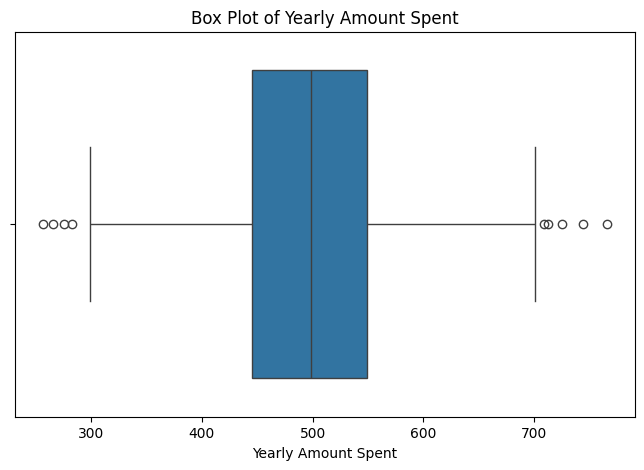

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(x=df['Yearly Amount Spent'])

plt.title('Box Plot of Yearly Amount Spent')
plt.xlabel('Yearly Amount Spent')

plt.show()

The box plot shows outliers on both the lower and upper sides of Yearly Amount Spent. These points represent customers with unusually low or high spending compared to the majority of customers.

# Correlation Analysis

In [ ]:
df.corr(numeric_only=True)

,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
Avg. Session Length,1.000000,-0.027826,-0.034987,0.060247,0.355088
Time on App,-0.027826,1.000000,0.082388,0.029143,0.499328
Time on Website,-0.034987,0.082388,1.000000,-0.047582,-0.002641
Length of Membership,0.060247,0.029143,-0.047582,1.000000,0.809084
Yearly Amount Spent,0.355088,0.499328,-0.002641,0.809084,1.000000


The analysis shows that Length of Membership has the strongest relationship with Yearly Amount Spent. Time on App and Avg. Session Length also show positive relationships, while Time on Website has almost no relationship.

#Line Plot using Matplotlib

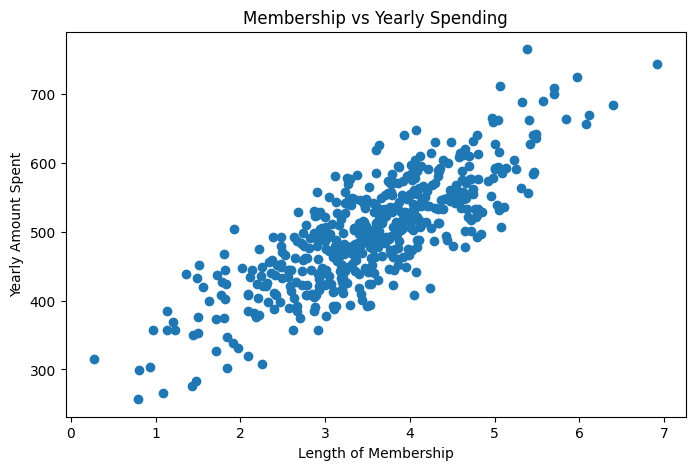

In [ ]:
plt.figure(figsize=(8,5))

plt.scatter(df['Length of Membership'],
            df['Yearly Amount Spent'])

plt.xlabel('Length of Membership')
plt.ylabel('Yearly Amount Spent')
plt.title('Membership vs Yearly Spending')

plt.show()

The scatter plot shows a positive relationship between Length of Membership and Yearly Amount Spent. Customers with longer memberships generally spend more annually.


#Distribution of Yearly Amount Spent

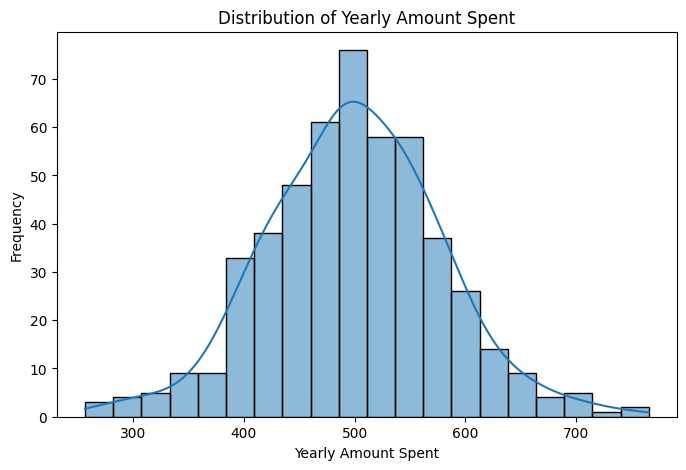

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(data=df, x='Yearly Amount Spent', kde=True)

plt.title('Distribution of Yearly Amount Spent')
plt.xlabel('Yearly Amount Spent')
plt.ylabel('Frequency')

plt.show()

#The histogram shows that most customers spend between 450 and 550 yearly. The distribution is approximately normal, with fewer customers spending very low or very high amounts.

#Time on App vs Yearly Amount Spent

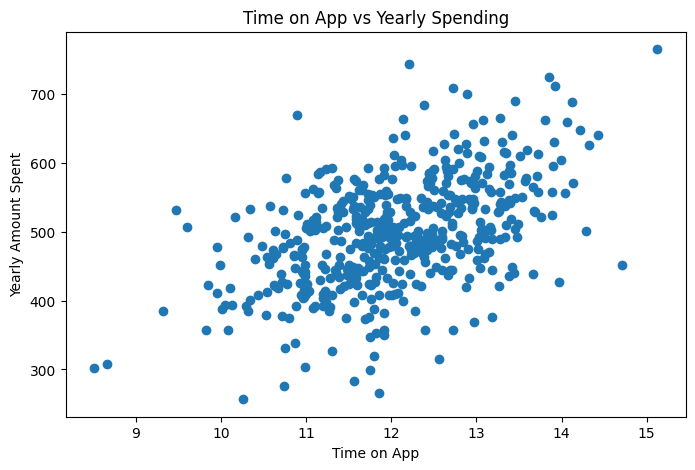

In [ ]:
plt.figure(figsize=(8,5))

plt.scatter(df['Time on App'],
            df['Yearly Amount Spent'])

plt.xlabel('Time on App')
plt.ylabel('Yearly Amount Spent')
plt.title('Time on App vs Yearly Spending')

plt.show()

The graph shows a positive relationship between time spent on the app and yearly spending. Customers who spend more time on the app generally tend to spend more money.

# Time on Website vs Yearly Amount Spent

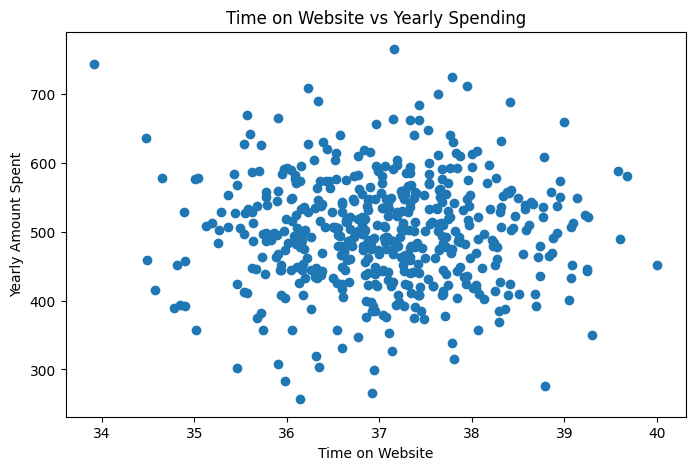

In [ ]:
plt.figure(figsize=(8,5))

plt.scatter(df['Time on Website'],
            df['Yearly Amount Spent'])

plt.xlabel('Time on Website')
plt.ylabel('Yearly Amount Spent')
plt.title('Time on Website vs Yearly Spending')

plt.show()

The graph shows a very weak relationship between time spent on the website and yearly spending. This suggests that website usage has little impact on customers' yearly spending.

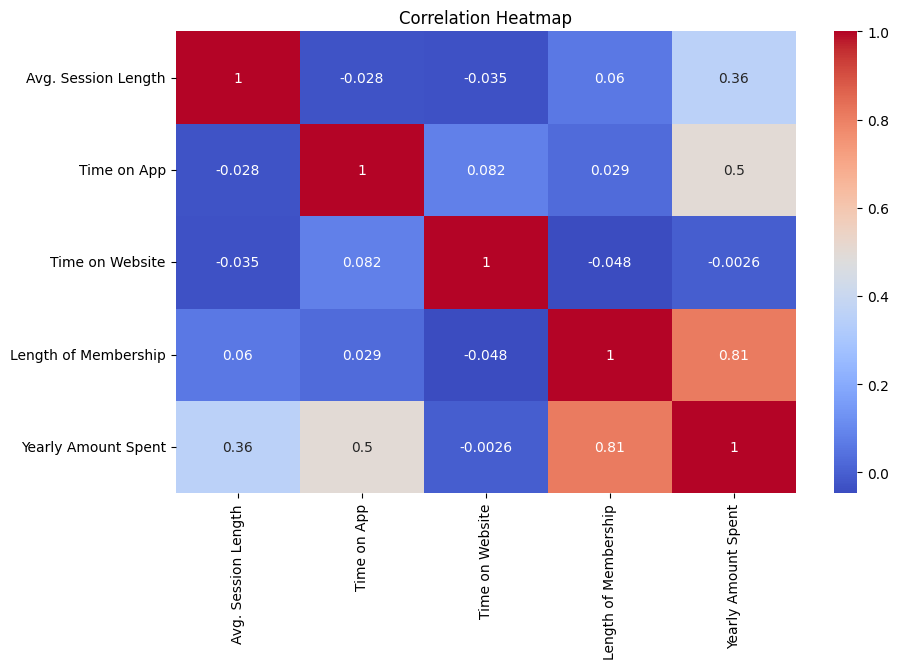

In [ ]:
plt.figure(figsize=(10,6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

The correlation heatmap shows the relationships between numerical variables. Length of Membership has the strongest positive correlation (0.81) with Yearly Amount Spent, while Time on Website has almost no correlation (-0.0026).

In [ ]:
np.mean(df['Yearly Amount Spent'])

np.float64(499.31403825859053)

NumPy's mean() function calculates the average yearly amount spent by customers. The result is approximately 499.31, which matches the average calculated using Pandas.

#Analysis Questions

    Univariate Analysis (3 Questions)


Q1. What is the average yearly amount spent by customers?

Q2. What is the distribution of customers' time spent on the mobile app?

Q3. What is the average length of customer membership?

    Bivariate Analysis (3 Questions)


Q4. What is the relationship between Time on App and Yearly Amount Spent?

Q5. What is the relationship between Time on Website and Yearly Amount Spent?

Q6. How does Length of Membership affect Yearly Amount Spent?

    Self-Selected Analysis (2 Questions)


Q7. Which customer activity has the strongest correlation with Yearly Amount Spent?

Q8. Do customers with longer membership periods generally spend more than customers with shorter memberships?

In [ ]:
#Q1: What is the average yearly amount spent by customers?
df['Yearly Amount Spent'].mean()

np.float64(499.31403825859053)

The average yearly amount spent by customers is approximately 499.31. This shows that customers spend around 499 on average per year.

In [ ]:
#Q2: What is the distribution of customers' time spent on the mobile app?
df['Time on App'].describe()

,Time on App
count,500.000000
mean,12.052488
std,0.994216
min,8.508152
25%,11.388153
50%,11.983231
75%,12.753850
max,15.126994


Customers spend an average of 12.05 units of time on the mobile app. Most customers spend approximately 11 to 13 units of time on the app, showing a fairly consistent usage pattern.

In [ ]:
# Q3: What is the average length of membership of customers?
df['Length of Membership'].mean()

np.float64(3.5334615559150566)

The average length of membership of customers is approximately 3.53 years. This shows that customers have been associated with the company for an average period of 3.5 years.

In [ ]:
# Q4: Is there a relationship between Time on App and Yearly Amount Spent?
df['Time on App'].corr(df['Yearly Amount Spent'])

np.float64(0.49932777005345036)

The correlation between Time on App and Yearly Amount Spent is approximately 0.50. This indicates a moderate positive relationship, meaning customers who spend more time on the app generally tend to spend more money yearly.

In [ ]:
# Q5: Is there a relationship between Time on Website and Yearly Amount Spent?
df['Time on Website'].corr(df['Yearly Amount Spent'])

np.float64(-0.0026408446721588536)

The correlation between Time on Website and Yearly Amount Spent is approximately -0.003. This indicates almost no relationship between the time customers spend on the website and their yearly spending.

In [ ]:
# Q6: What is the correlation between Length of Membership and Yearly Amount Spent?
df['Length of Membership'].corr(df['Yearly Amount Spent'])

np.float64(0.8090835682475813)

The correlation between Length of Membership and Yearly Amount Spent is approximately 0.81. This indicates a strong positive relationship, meaning customers with longer membership periods generally spend more money yearly.

In [ ]:
# Q7: Which customer activity has the strongest correlation with Yearly Amount Spent?
df.corr(numeric_only=True)['Yearly Amount Spent'].sort_values(ascending=False)

,Yearly Amount Spent
Yearly Amount Spent,1.000000
Length of Membership,0.809084
Time on App,0.499328
Avg. Session Length,0.355088
Time on Website,-0.002641


Length of Membership has the strongest correlation with Yearly Amount Spent, with a correlation value of approximately 0.81. This shows that membership duration is the strongest factor related to yearly customer spending.

In [ ]:
# Q8: Do customers with longer membership periods generally spend more than customers with shorter membership?
df.groupby(pd.cut(df['Length of Membership'], bins=3), observed=False)['Yearly Amount Spent'].mean()

,Yearly Amount Spent
Length of Membership,
"(0.263, 2.487]",396.108187
"(2.487, 4.705]",502.334658
"(4.705, 6.923]",604.499191


Yes, customers with longer membership periods generally spend more money. Customers with shorter memberships spend approximately 396.11, while customers with medium memberships spend 502.33 and longer memberships spend 604.50 on average. This confirms that longer membership is associated with higher yearly spending.

 # Final Conclusion
The analysis shows that customer spending is strongly influenced by the length of membership. Customers with longer memberships tend to spend more yearly. Time spent on the mobile app also has a moderate positive relationship with yearly spending, while time spent on the website has almost no relationship. The average yearly spending is approximately 499.31. Overall, customer membership duration is the strongest factor related to yearly spending.
